## Data Inspection and Season Mapping
This cell prints the shape, data types, missing values per column, and the sorted unique values of `season` and `weathersit`. To work out what each `season` code means, I cross-tabulate month against season code and list the dates where the code changes. The changes fall on Mar 21, Jun 21, Sep 23 and Dec 21 (the equinoxes and solstices). Code 1 covers Dec 21 – Mar 20, so **1 = Winter** (not "spring" as the original dataset documentation says), 2 = Spring, 3 = Summer, 4 = Fall. The mapping is built from the data by taking the month with the most days for each code and converting that month to its Northern Hemisphere season.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

df = pd.read_csv(
    "https://raw.githubusercontent.com/leahdyhrkopp1/LeahDyhrkopp/main/day_missing.csv"
)

# 1. Shape
print("Shape:", df.shape)

# 2. Data types
print("\nData types:")
print(df.dtypes)

# 3. Missing values per column
print("\nMissing values per column:")
print(df.isna().sum())

# 4. Sorted unique values of season and weathersit
print("\nUnique season values:", sorted(df["season"].unique().tolist()))
print("Unique weathersit values:", sorted(df["weathersit"].unique().tolist()))

# 5. Evidence for the season mapping
print("\nDays per month (rows) for each season code (columns):")
month_by_season = pd.crosstab(df["mnth"], df["season"])
print(month_by_season)

print("\nDates where the season code changes:")
season_changes = df["season"].ne(df["season"].shift())
print(df.loc[season_changes, ["dteday", "mnth", "season"]])

# Month that contains the most days of each season code, then that
# month's Northern Hemisphere season name
month_to_season = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall",
}
main_month = month_by_season.idxmax()
season_map = {
    int(code): month_to_season[int(month)]
    for code, month in main_month.items()
}
print("\nFinal season mapping:")
print(season_map)

Shape: (731, 16)

Data types:
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual        float64
registered    float64
cnt           float64
dtype: object

Missing values per column:
instant        0
dteday         0
season         0
yr             0
mnth           0
holiday        0
weekday        0
workingday     0
weathersit     0
temp          18
atemp         21
hum            8
windspeed     21
casual        12
registered    14
cnt           17
dtype: int64

Unique season values: [1, 2, 3, 4]
Unique weathersit values: [1, 2, 3]

Days per month (rows) for each season code (columns):
season   1   2   3   4
mnth                  
1       62   0   0   0
2       57   0   0   0
3       40  22   0   0
4        0  60   0   0
5        0  62   0   0
6  

## Q1. Four-Moment Table
Continuous variables are the numeric columns with more than 8 distinct non-missing values. This follows the rule exactly, so it includes `instant` (731 values) and `mnth` (12 values). For each one the table shows the mean, standard deviation, skewness, and kurtosis (Fisher's definition, excess kurtosis, where a normal distribution = 0), rounded to 4 decimals.

In [2]:
numeric_cols = df.select_dtypes(include="number").columns
cont_cols = [col for col in numeric_cols if df[col].nunique() > 8]

moments = pd.DataFrame({
    "mean": df[cont_cols].mean(),
    "std": df[cont_cols].std(),
    "skew": df[cont_cols].skew(),
    "kurtosis": df[cont_cols].kurt(),
}).round(4)
print(moments)

                 mean        std     skew  kurtosis
instant      366.0000   211.1658   0.0000   -1.2000
mnth           6.5198     3.4519  -0.0081   -1.2091
temp           0.8209     3.7898  12.5146  162.4505
atemp          0.4747     0.1637  -0.1356   -0.9854
hum            0.6282     0.1425  -0.0772   -0.0491
windspeed      0.1909     0.0777   0.6692    0.4034
casual       846.4312   687.1555   1.2700    1.3391
registered  3654.6402  1557.7495   0.0422   -0.7027
cnt         4474.5224  1931.4106  -0.0329   -0.8005


## Q2. Kurtosis Flag for Possible Outliers
Using the Q1 kurtosis values, these are the variables with |kurtosis| > 1.8. Only `temp` qualifies (kurtosis = 162.4505), which points to extreme outliers in that column.

In [3]:
high_kurt = moments.loc[moments["kurtosis"].abs() > 1.8, "kurtosis"]

if high_kurt.empty:
    print("No variable has an absolute kurtosis greater than 1.8.")
else:
    print("Variables with |kurtosis| > 1.8:", list(high_kurt.index))
    print(high_kurt)

Variables with |kurtosis| > 1.8: ['temp']
temp    162.4505
Name: kurtosis, dtype: float64


## Q3. Outliers Replaced with Missing Values
For each continuous variable from Q1, I compute Q1, Q3 and IQR = Q3 − Q1 by hand. A value is an outlier if it is below Q1 − 2.1×IQR or above Q3 + 2.1×IQR. Each outlier is replaced with `np.nan`. The table lists only the variables that lost at least one value.

In [4]:
outlier_counts = {}

for col in cont_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 2.1 * iqr
    upper = q3 + 2.1 * iqr
    is_outlier = (df[col] < lower) | (df[col] > upper)
    n_outliers = int(is_outlier.sum())
    if n_outliers > 0:
        df.loc[is_outlier, col] = np.nan
        outlier_counts[col] = n_outliers

outlier_table = pd.DataFrame({
    "variable": list(outlier_counts.keys()),
    "outliers_replaced": list(outlier_counts.values()),
})
print(outlier_table.to_string(index=False))

 variable  outliers_replaced
     temp                  6
      hum                  1
windspeed                  1
   casual                 14


## Q4. Mean Imputation (Affected Columns Only)
Only the columns that had outliers replaced in Q3 (`temp`, `hum`, `windspeed`, `casual`) are imputed. Each is filled with its post-Q3 mean, which is the mean of the remaining non-missing values. No other columns are changed. The check afterwards confirms these columns have zero missing values.

In [5]:
imputed_cols = list(outlier_counts.keys())

for col in imputed_cols:
    df[col] = df[col].fillna(df[col].mean())

print("Missing values in imputed columns:")
print(df[imputed_cols].isna().sum())

Missing values in imputed columns:
temp         0
hum          0
windspeed    0
casual       0
dtype: int64


## Q5. Post-Imputation Kurtosis Check
This compares each modified variable's kurtosis before any treatment (from Q1) with its kurtosis after outlier removal and mean imputation. The difference is after − before, and the table is sorted by absolute difference, largest first.

In [6]:
kurt_compare = pd.DataFrame({
    "kurtosis_before": moments.loc[imputed_cols, "kurtosis"],
    "kurtosis_after": df[imputed_cols].kurt().round(4),
})
kurt_compare["difference"] = (
    kurt_compare["kurtosis_after"] - kurt_compare["kurtosis_before"]
).round(4)
kurt_compare = kurt_compare.sort_values(
    "difference", key=lambda s: s.abs(), ascending=False
)
print(kurt_compare)

           kurtosis_before  kurtosis_after  difference
temp              162.4505         -1.0611   -163.5116
casual              1.3391          0.9124     -0.4267
hum                -0.0491         -0.4127     -0.3636
windspeed           0.4034          0.2662     -0.1372


**Interpretation:** `temp` changed the most. Its kurtosis fell from 162.4505 to −1.0611 (difference −163.5116). Its tails became **much lighter**: it went from extremely heavy-tailed (caused by a few impossible values such as 58.75 on a 0–1 scale) to slightly light-tailed, flatter than a normal distribution. All four modified variables ended up with lower kurtosis, so every one of them has lighter tails after treatment.

## Q6. Datetime Index
Convert `dteday` (format M/D/YYYY) to pandas datetime, set it as the index, and drop the original column if it is still there. `df.info()` confirms the index is a `DatetimeIndex`.

In [7]:
df["dteday"] = pd.to_datetime(df["dteday"], format="%m/%d/%Y")
df = df.set_index("dteday")

if "dteday" in df.columns:
    df = df.drop(columns="dteday")

df.info()
print("\nIndex type:", type(df.index).__name__)

<class 'pandas.DataFrame'>
DatetimeIndex: 731 entries, 2011-01-01 to 2012-12-31
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   season      731 non-null    int64  
 2   yr          731 non-null    int64  
 3   mnth        731 non-null    int64  
 4   holiday     731 non-null    int64  
 5   weekday     731 non-null    int64  
 6   workingday  731 non-null    int64  
 7   weathersit  731 non-null    int64  
 8   temp        731 non-null    float64
 9   atemp       710 non-null    float64
 10  hum         731 non-null    float64
 11  windspeed   731 non-null    float64
 12  casual      731 non-null    float64
 13  registered  717 non-null    float64
 14  cnt         714 non-null    float64
dtypes: float64(7), int64(8)
memory usage: 91.4 KB

Index type: DatetimeIndex


## Q7. Scatter-Plot Matrix by Weather Situation
This is a scatter-plot matrix of `cnt`, `temp`, `hum`, `windspeed` and `atemp`, with points colored by `weathersit` using a discrete palette. The names come from the dataset documentation: 1 = Clear, 2 = Mist, 3 = Light Rain or Snow, 4 = Heavy Rain or Snow. The first cell showed that only codes 1–3 appear in this data, so the legend shows three categories.

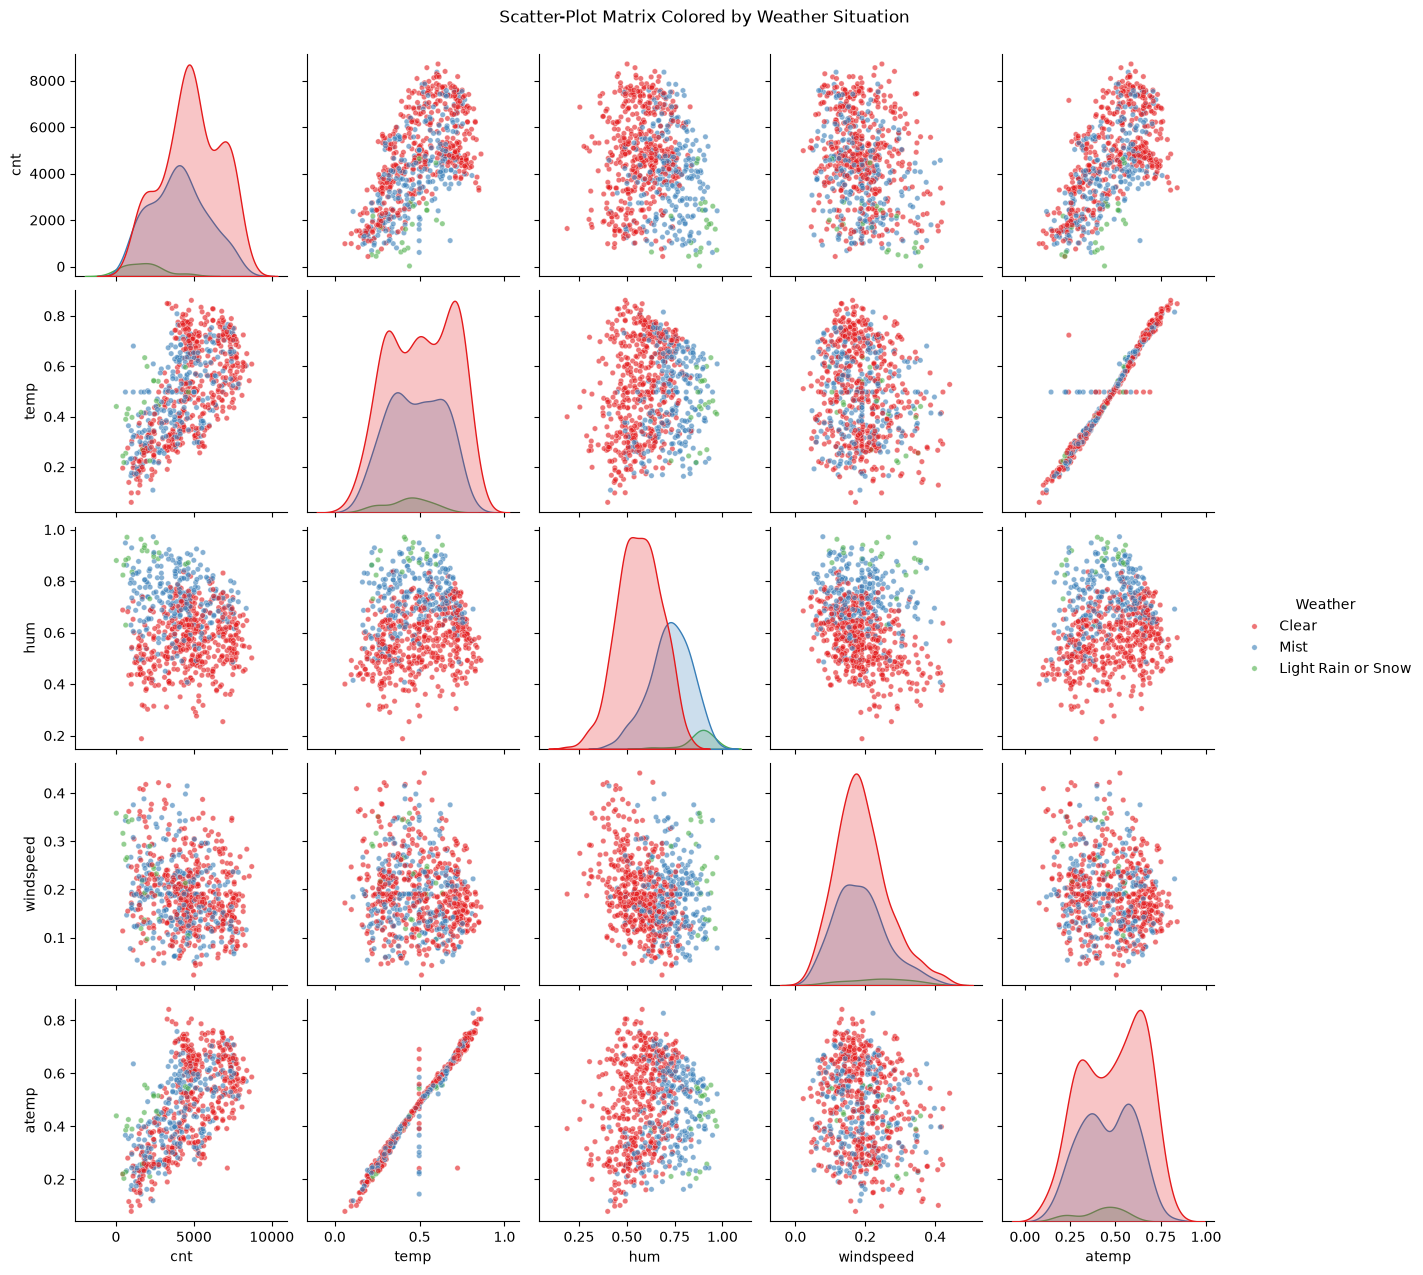

In [8]:
weather_map = {
    1: "Clear",
    2: "Mist",
    3: "Light Rain or Snow",
    4: "Heavy Rain or Snow",
}
weather_order = [
    weather_map[code] for code in sorted(df["weathersit"].unique())
]

plot_df = df[["cnt", "temp", "hum", "windspeed", "atemp"]].copy()
plot_df["Weather"] = df["weathersit"].map(weather_map)

grid = sns.pairplot(
    plot_df,
    hue="Weather",
    hue_order=weather_order,
    palette="Set1",
    plot_kws={"s": 15, "alpha": 0.6},
)
grid.figure.suptitle(
    "Scatter-Plot Matrix Colored by Weather Situation", y=1.02
)
plt.show()

## Q8. Boxplots of Daily Rentals by Season
Boxplots of `cnt` for each season, in the order of the integer coding found in the first cell (1 = Winter → 2 = Spring → 3 = Summer → 4 = Fall). The tick labels come from `season_map`. Winter has clearly the lowest rentals, which also supports the mapping.

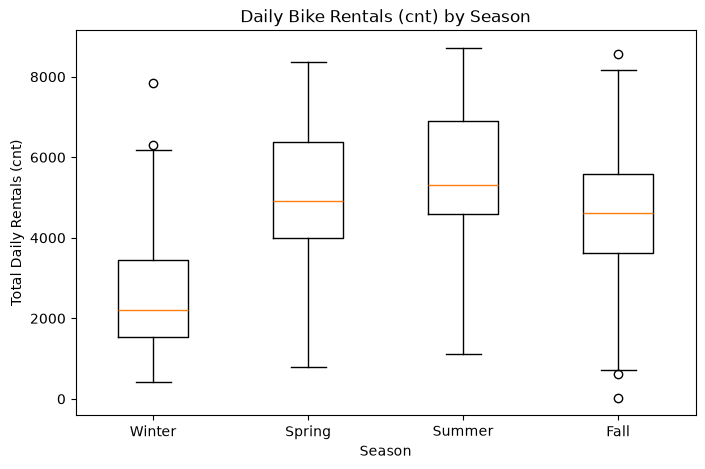

In [9]:
season_order = sorted(season_map)
season_labels = [season_map[code] for code in season_order]
cnt_by_season = [
    df.loc[df["season"] == code, "cnt"].dropna() for code in season_order
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(cnt_by_season)
ax.set_xticks(range(1, len(season_labels) + 1))
ax.set_xticklabels(season_labels)
ax.set_title("Daily Bike Rentals (cnt) by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Total Daily Rentals (cnt)")
plt.show()

## Q9. Casual vs Registered Rentals with Marginal Histograms
Scatter plot of `casual` (x) against `registered` (y), colored by `workingday` (0 = Non-working day, 1 = Working day), with a histogram of each variable in the margins.

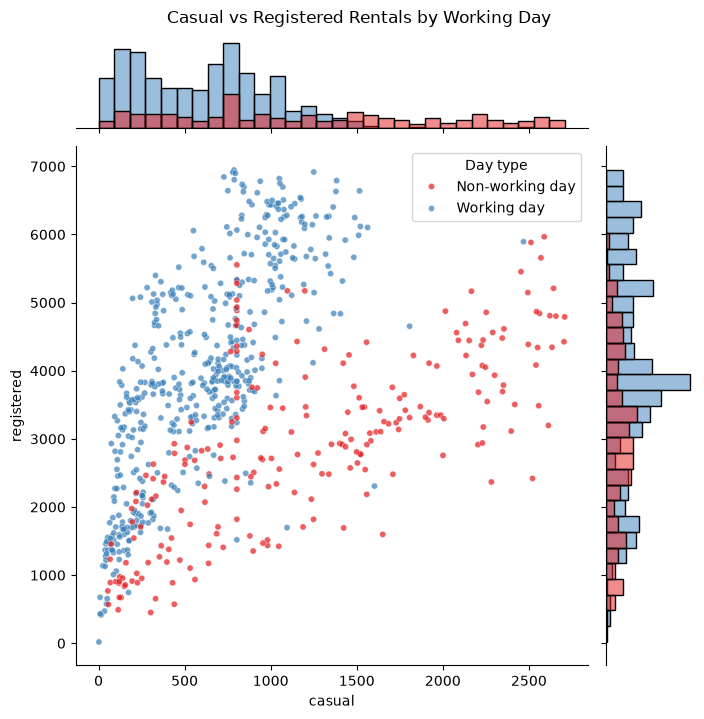

In [10]:
day_type = df["workingday"].map({0: "Non-working day", 1: "Working day"})
joint_df = df[["casual", "registered"]].assign(day_type=day_type)

grid = sns.JointGrid(
    data=joint_df,
    x="casual",
    y="registered",
    hue="day_type",
    palette="Set1",
    height=7,
)
grid.plot_joint(sns.scatterplot, s=20, alpha=0.7)
grid.plot_marginals(sns.histplot, bins=30, alpha=0.5)
grid.ax_joint.legend(title="Day type")
grid.figure.suptitle("Casual vs Registered Rentals by Working Day", y=1.02)
plt.show()

## Q10. Treemap of Total Rentals by Weather Situation
One rectangle per distinct `weathersit` value, sized by the total `cnt` for that weather situation, labeled with the weather name and given its own color. Only Clear, Mist and Light Rain or Snow appear, because Heavy Rain or Snow (code 4) never occurs in the data.

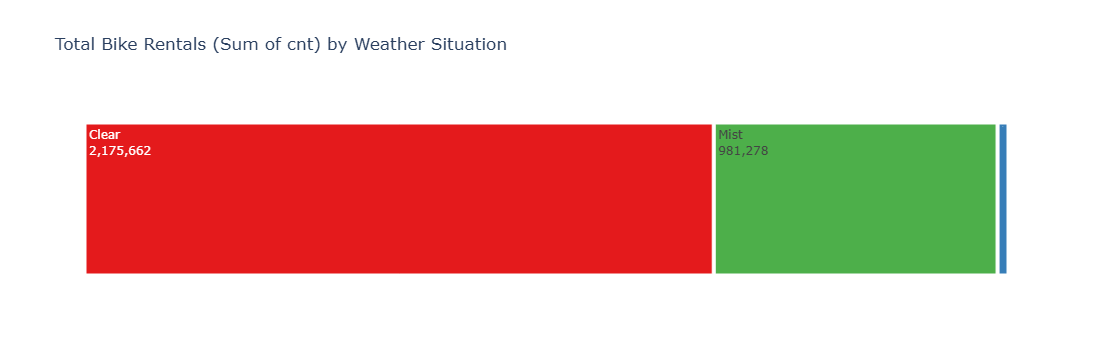

In [11]:
weather_cnt = df.groupby("weathersit")["cnt"].sum().reset_index()
weather_cnt["Weather"] = weather_cnt["weathersit"].map(weather_map)

fig = px.treemap(
    weather_cnt,
    path=["Weather"],
    values="cnt",
    color="Weather",
    color_discrete_sequence=px.colors.qualitative.Set1,
    title="Total Bike Rentals (Sum of cnt) by Weather Situation",
)
fig.update_traces(textinfo="label+value")
fig.show()